## Building Energy Consumption Prediction
### 1. Understanding the Dataset

We will inspect the cleaned dataset from Day 1 to understand its structure, available features, and missing values before selecting a prediction target

### Dataset Background and Cleaning

This project uses the cleaned dataset produced during the Day 1 assignment. The dataset contains information about building energy consumption.

### Dataset Cleaning — Day 1

The original UK energy-consumption dataset was inspected and cleaned before modelling.

* **Duplicate removal:** Removed **2 exact duplicate rows** using `df_clean.drop_duplicates()`. The cleaned dataset contained **49,998 rows and 96 columns**, with no duplicate rows remaining.
* **Missing values:** Missing-value counts and percentages were calculated. 86 of 96 columns contained missing data.
* **Installation dates:** Missing values in `PV_DATE`, `LI_DATE` and `CWI_DATE` were retained because they were associated with properties without the corresponding installations.
* **Energy consumption:** Gas and electricity consumption columns were checked for negative values; none were found.
* **Categorical values:** Property characteristics, installation indicators, conservatory flags and deprivation bands were checked for unexpected values and meaningful missing data.
* **Export:** The resulting dataset was saved as `anon2026_50k_cleaned.csv`.

**Limitation:** Missing values were investigated but not generally imputed. They will be handled within the supervised-learning preprocessing pipeline where appropriate.



## 2. Load and Inspect the Dataset

We load the cleaned Day 1 dataset and inspect its dimensions, column names, data types, and missing values. This helps us understand the available information before defining the prediction task.


In [3]:
import pandas as pd

df = pd.read_csv("../data/anon2026_50k_cleaned.csv")

print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame(name="Data Type"))

print("\nMissing values per column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

display(df.head())

Dataset dimensions: (49998, 96)

Column names:
['PROP_TYPE', 'PROP_AGE_BAND', 'FLOOR_AREA_BAND', 'CONSERVATORY_FLAG', 'COUNCIL_TAX_BAND', 'IMD_BAND_ENG', 'IMD_BAND_WALES', 'REGION', 'EPC', 'LI_FLAG', 'LI_DATE', 'CWI_FLAG', 'CWI_DATE', 'PV_FLAG', 'PV_DATE', 'MAIN_HEAT_FUEL', 'Gcons2024', 'Gcons2023', 'Gcons2022', 'Gcons2021', 'Gcons2020', 'Gcons2019', 'Gcons2018', 'Gcons2017', 'Gcons2016', 'Gcons2015', 'Gcons2014', 'Gcons2013', 'Gcons2012', 'Gcons2011', 'Gcons2010', 'Gcons2009', 'Gcons2008', 'Gcons2007', 'Gcons2006', 'Gcons2005', 'GasValFlag2024', 'GasValFlag2023', 'GasValFlag2022', 'GasValFlag2021', 'GasValFlag2020', 'GasValFlag2019', 'GasValFlag2018', 'GasValFlag2017', 'GasValFlag2016', 'GasValFlag2015', 'GasValFlag2014', 'GasValFlag2013', 'GasValFlag2012', 'GasValFlag2011', 'GasValFlag2010', 'GasValFlag2009', 'GasValFlag2008', 'GasValFlag2007', 'GasValFlag2006', 'GasValFlag2005', 'Econs2024', 'Econs2023', 'Econs2022', 'Econs2021', 'Econs2020', 'Econs2019', 'Econs2018', 'Econs2017', '

,Data Type
PROP_TYPE,str
PROP_AGE_BAND,int64
FLOOR_AREA_BAND,int64
CONSERVATORY_FLAG,float64
COUNCIL_TAX_BAND,str
...,...
ElecValFlag2009,str
ElecValFlag2008,str
ElecValFlag2007,str
ElecValFlag2006,str



Missing values per column:


,Missing Values
PROP_TYPE,0
PROP_AGE_BAND,0
FLOOR_AREA_BAND,0
CONSERVATORY_FLAG,40461
COUNCIL_TAX_BAND,0
...,...
ElecValFlag2009,770
ElecValFlag2008,770
ElecValFlag2007,770
ElecValFlag2006,770


,PROP_TYPE,PROP_AGE_BAND,FLOOR_AREA_BAND,CONSERVATORY_FLAG,COUNCIL_TAX_BAND,IMD_BAND_ENG,IMD_BAND_WALES,REGION,EPC,LI_FLAG,...,ElecValFlag2014,ElecValFlag2013,ElecValFlag2012,ElecValFlag2011,ElecValFlag2010,ElecValFlag2009,ElecValFlag2008,ElecValFlag2007,ElecValFlag2006,ElecValFlag2005
0,Semi detached,3,2,NaN,A,3.0,NaN,E12000004,C,0,...,V,V,V,V,V,V,L,V,V,V
1,Mid terrace,1,3,NaN,E,1.0,NaN,E12000007,No EPC,0,...,V,V,V,V,V,V,V,V,V,V
2,Detached,4,3,0.0,E,3.0,NaN,E12000005,A/B,0,...,O,O,O,O,O,O,O,O,O,O
3,Semi detached,4,2,0.0,C,4.0,NaN,E12000004,A/B,0,...,O,O,O,O,O,O,O,O,O,O
4,Bungalow,2,2,NaN,D,5.0,NaN,E12000008,D,1,...,V,V,V,V,V,V,V,V,V,V


### 3. Target Variable Assessment

Before selecting the input features, we need to examine the target variable and understand its data quality.

Our target is `Gcons2024`, which represents the property's annual gas consumption in 2024.

We will check:

* **Data type:** Confirm that the target is numerical.
* **Missing values:** Identify properties without recorded gas consumption.
* **Statistical summary:** Understand the distribution and range of consumption values.
* **Zero values:** Identify properties with recorded zero consumption.
* **Negative values:** Check for potentially invalid consumption records.

These checks will help us decide which records are suitable for model training. We will investigate unusual values before deciding how to handle them.


In [4]:
target = "Gcons2024"

print("Target data type:", df[target].dtype)
print("Missing target values:", df[target].isna().sum())

print("\nTarget statistics:")
display(df[target].describe())

print("\nZero-consumption records:", (df[target] == 0).sum())
print("Negative-consumption records:", (df[target] < 0).sum())

Target data type: float64
Missing target values: 10496

Target statistics:


count    39502.000000
mean     11208.817275
std       6719.565173
min       1000.000000
25%       6600.000000
50%      10000.000000
75%      14300.000000
max      49900.000000
Name: Gcons2024, dtype: float64


Zero-consumption records: 0
Negative-consumption records: 0


### Findings

The dataset contains 49,998 properties, of which 39,502 have recorded gas consumption for 2024. The remaining 10,496 records have missing target values.

The recorded consumption values range from 1,000 to 49,900 kWh, with a median of 10,000 kWh. No zero or negative consumption values were found.

**Decision:** We will investigate the missing target values and the 2024 gas validation flags before preparing the training dataset. We will not impute missing target values, because doing so would introduce artificial values into the quantity we want to predict.


In [5]:
print("2024 gas validation flags:")
display(df["GasValFlag2024"].value_counts(dropna=False))

print("\nValidation flags for records with missing gas consumption:")
display(
    df.loc[df["Gcons2024"].isna(), "GasValFlag2024"]
    .value_counts(dropna=False)
)

print("\nValidation flags for records with recorded gas consumption:")
display(
    df.loc[df["Gcons2024"].notna(), "GasValFlag2024"]
    .value_counts(dropna=False)
)

2024 gas validation flags:


GasValFlag2024
V      37186
NaN     8658
E       2316
L       1015
O        609
G        214
Name: count, dtype: int64


Validation flags for records with missing gas consumption:


GasValFlag2024
NaN    8658
L      1015
O       609
G       214
Name: count, dtype: int64


Validation flags for records with recorded gas consumption:


GasValFlag2024
V    37186
E     2316
Name: count, dtype: int64

### Understanding Missing Gas Consumption

The 2024 gas validation flags explain the missing target values.

Records with validation flags `V` and `E` have recorded gas consumption. Records with flags `L`, `G`, or `O`, and records with missing validation flags, have missing consumption values.

The missing values are therefore associated with reporting thresholds, specified missing-data conditions, or an unmatched gas meter, rather than simply being random gaps.

**Decision:** For the initial regression model, we will retain records with available `Gcons2024` values, including both valid and estimated consumption. We will not impute missing target values.

We will investigate the suitability of the input features separately before preparing the training dataset.


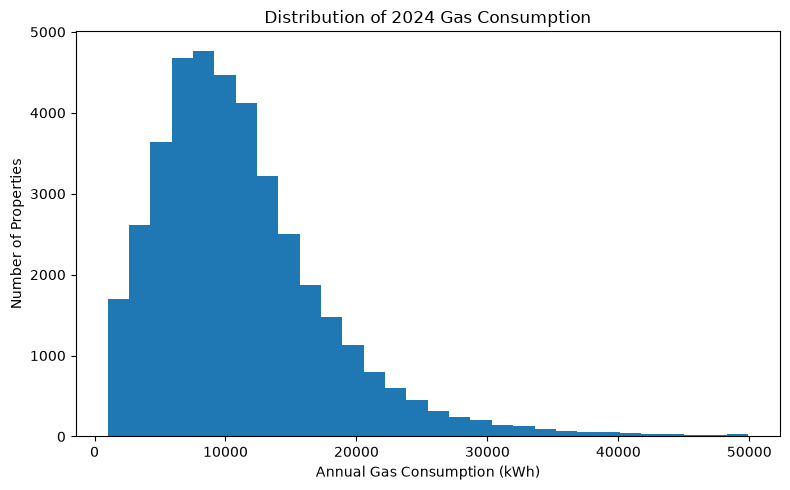

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["Gcons2024"].dropna(), bins=30)

plt.xlabel("Annual Gas Consumption (kWh)")
plt.ylabel("Number of Properties")
plt.title("Distribution of 2024 Gas Consumption")

plt.tight_layout()
plt.show()

### Target Distribution Analysis

The histogram shows that annual gas consumption is right-skewed. Most properties have consumption values concentrated around 6,000–12,000 kWh, while a smaller number have substantially higher consumption.

The distribution has a long right tail, with some properties approaching 50,000 kWh.

**Modelling implications:**

* We will use Mean Absolute Error (MAE) as our primary evaluation metric.
* We will retain high-consumption records unless further investigation identifies a data-quality issue.
* We will compare multiple regression model families to determine which performs best on this dataset.


## 4. Feature Selection and Leakage Prevention

### Prediction objective

Predict annual gas consumption in 2024 using building characteristics and historical gas consumption.

**Target variable (`y`):** `Gcons2024`

**Candidate input features (`X`):**

* Building characteristics: `PROP_TYPE`, `PROP_AGE_BAND`, `FLOOR_AREA_BAND`, `COUNCIL_TAX_BAND`, `REGION`, `MAIN_HEAT_FUEL`
* Historical gas consumption: `Gcons2023`, `Gcons2022`, `Gcons2021`

### Leakage prevention

We will exclude:

* `Gcons2024`, because it is the target.
* `GasValFlag2024`, because it describes the target year's gas-consumption data.
* All electricity-consumption columns and electricity-validation flags.
* Other validation flags initially, to keep the first model focused on building characteristics and historical gas consumption.

We will inspect missing values in the candidate features before constructing the training dataset. All preprocessing will be fitted using training data only.


## 5. Inspect Missing Values in Candidate Features

Before preparing the training dataset, we need to check the availability of our selected input features.

Our candidate features include building characteristics and historical gas consumption from 2021–2023.

We will examine:

* The number of missing values in each feature.
* How many records have complete historical gas-consumption data.
* Whether missing values need to be handled during preprocessing.

We will retain records with a valid `Gcons2024` target and handle missing input features within the machine-learning pipeline to avoid data leakage.


In [9]:
# Candidate input features
building_features = [
    "PROP_TYPE",
    "PROP_AGE_BAND",
    "FLOOR_AREA_BAND",
    "COUNCIL_TAX_BAND",
    "REGION",
    "MAIN_HEAT_FUEL"
]

historical_gas_features = [
    "Gcons2023",
    "Gcons2022",
    "Gcons2021"
]

features = building_features + historical_gas_features

# Calculate missing values and percentages
missing_count = df[features].isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percentage
})

# Display only features with missing values, highest percentage first
missing_report = missing_report[missing_report["Missing Values"] > 0]
missing_report = missing_report.sort_values(
    by="Missing Percentage (%)",
    ascending=False
)

print("Missing values in candidate features:")
display(missing_report.round(2))

# Check historical gas-data availability
print("\nMissing historical gas values:")
display(df[historical_gas_features].isnull().sum())

print(
    "\nRecords with all three historical gas values:",
    df[historical_gas_features].notnull().all(axis=1).sum()
)

Missing values in candidate features:


,Missing Values,Missing Percentage (%)
Gcons2021,10814,21.63
Gcons2022,10647,21.29
Gcons2023,10552,21.10



Missing historical gas values:


Gcons2023    10552
Gcons2022    10647
Gcons2021    10814
dtype: int64


Records with all three historical gas values: 38117


### Historical Feature Missingness Findings

Approximately 21% of the original dataset has missing historical gas-consumption values for each of the three selected years.

* `Gcons2021`: 21.63% missing
* `Gcons2022`: 21.29% missing
* `Gcons2023`: 21.10% missing

A total of 38,117 properties have complete historical consumption data for all three years.

**Decision:** We will retain records with an observed 2024 target and use median imputation for missing historical input values inside the preprocessing pipeline. This allows us to preserve more training records without imputing the target variable.


## 6. Prepare Data for Modelling

We will prepare the input features (`X`) and target (`y`) before splitting the dataset.

Records without a recorded `Gcons2024` target cannot be used for supervised regression, so these records will be excluded.

Missing historical gas-consumption values will not be filled at this stage. Instead, median imputation will be fitted on the training data within the preprocessing pipeline to prevent data leakage.


In [11]:
# Keep records with a known target
model_df = df.dropna(subset=["Gcons2024"]).copy()

# Separate features and target
X = model_df[features]
y = model_df["Gcons2024"]

print("Original dataset:", df.shape)
print("Modelling dataset:", model_df.shape)
print("Input features:", X.shape)
print("Target values:", y.shape)
print("Missing target values:", y.isna().sum())

Original dataset: (49998, 96)
Modelling dataset: (39502, 96)
Input features: (39502, 9)
Target values: (39502,)
Missing target values: 0
